# Experiment A: Unsupervised Buzzer Detection
**Goal:** Detect suspicious accounts tanpa supervised learning

**Method:** Rule-based scoring + clustering

**Data:** 416 posts, 251 accounts (karhutla campaign)

## 1. Setup

In [2]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print("Setup complete")

Setup complete


## 2. Load Data & Features

In [ ]:
posts = pd.read_csv("../data/features/posts_with_features.csv")
posts["date"] = pd.to_datetime(posts["date"])
posts["account_id"] = posts["account_id"].astype(str)

try:
    accounts = pd.read_csv("../data/features/account_features.csv")
    print(f"Loaded: {len(posts)} posts, {len(accounts)} accounts with features")
except FileNotFoundError:
    print("account_features.csv not found, will generate...")
    accounts = None

posts.head()

Loaded: 416 posts, 248 accounts with features


,post_id,account_id,id,user_id,source_post_id,source_account_id,target_post_id,target_account_id,target_username,relation_type,...,is_reply,is_quote,isu,query,hashtags,n_tags,body_clean,body_len,has_url,date_only
0,2117944532226740610,2095858716981841921,2117944532226740610,2095858716981841921,2117944532226740610,2095858716981841921,2.117898e+18,2.028423e+18,naraeraa,quote,...,False,True,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,"['#prayforkalimantan', '#PRAYFORPAPUA']",2,#prayforkalimantan\n#PRAYFORPAPUA \nFor the fo...,81,False,2026-11-04
1,2117897733009006713,2028423057505910784,2117897733009006713,2028423057505910784,2117897733009006713,2028423057505910784,NaN,NaN,NaN,original,...,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,[],0,ALL EYES ON KALIMANTAN ❤️‍🔥❤️‍🔥❤️‍🔥 https://t....,59,True,2026-11-04
2,2117927960212865525,1546272513302208513,2117927960212865525,1546272513302208513,2117927960212865525,1546272513302208513,NaN,NaN,NaN,original,...,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,"['#PRAYFORLAMPUNG', '#PRAYFORSULAWESI', '#PRAY...",15,#PRAYFORLAMPUNG\n#PRAYFORSULAWESI\n#PRAYFORKAL...,261,False,2026-11-04
3,2117922457629954389,903456043304239104,2117922457629954389,903456043304239104,2117922457629954389,903456043304239104,2.117877e+18,2.105582e+18,ccaramelh2h,quote,...,False,True,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,"['#PRAYFORLAMPUNG', '#PRAYFORSULAWESI', '#PRAY...",12,Terus staff Pemprovnya kek gini\nCr : @/selasa...,280,True,2026-11-04
4,2117877002040754390,2105581778903945216,2117877002040754390,2105581778903945216,2117877002040754390,2105581778903945216,NaN,NaN,NaN,original,...,False,False,prayforkalimantan,https://x.com/hashtag/PRAYFORKALIMANTAN?src=ha...,['#INDONESIASADAR'],1,🚨Update Demo\nSamarinda Kaltim ✊🏼🇮🇩❤️‍🔥🔥\n\nRa...,121,True,2026-11-04


## 3. Generate Account-Level Features

In [ ]:
acc_features = posts.groupby("account_id").agg(
    username=("username", "first"),
    n_posts=("post_id", "count"),
    avg_tags=("n_tags", "mean"),
    avg_body_len=("body_len", "mean"),
    n_replies=("is_reply", "sum"),
    n_quotes=("is_quote", "sum"),
    n_originals=("relation_type", lambda x: (x == "original").sum()),
    first_post=("date", "min"),
    last_post=("date", "max"),
    followers=("followers", "first"),
    following=("following", "first")
).reset_index()

acc_features["active_hours"] = (acc_features["last_post"] - acc_features["first_post"]).dt.total_seconds() / 3600
acc_features["post_rate"] = acc_features["n_posts"] / (acc_features["active_hours"] + 0.1)
acc_features["follower_ratio"] = acc_features["followers"] / (acc_features["following"] + 1)

print(f"Account features generated: {len(acc_features)} accounts")
acc_features.describe()

Account features generated: 248 accounts


,n_posts,avg_tags,avg_body_len,n_replies,n_quotes,n_originals,followers,following,active_hours,post_rate,follower_ratio
count,248.000000,248.000000,248.000000,248.000000,248.000000,248.000000,2.480000e+02,248.000000,248.000000,248.000000,2.480000e+02
mean,1.677419,5.150460,196.257078,0.169355,0.383065,1.125000,1.929954e+05,1938.850806,26.424747,8.494798,9.533226e+03
std,2.397868,5.025368,147.475162,0.453895,0.945068,2.062903,2.693173e+06,3408.263833,92.326806,4.003495,1.494056e+05
min,1.000000,0.000000,18.000000,0.000000,0.000000,0.000000,1.000000e+00,1.000000,0.000000,0.003958,3.144654e-02
25%,1.000000,1.000000,120.750000,0.000000,0.000000,0.000000,1.737500e+02,167.250000,0.000000,10.000000,7.808759e-01
50%,1.000000,2.775000,203.000000,0.000000,0.000000,1.000000,1.012500e+03,575.500000,0.000000,10.000000,1.125523e+00
75%,1.000000,10.000000,248.250000,0.000000,0.000000,1.000000,5.028250e+03,2173.250000,0.000000,10.000000,2.789248e+00
max,23.000000,15.000000,2002.000000,3.000000,8.000000,22.000000,4.235188e+07,22560.000000,575.533611,27.692308,2.352882e+06


## 4. Network Features

In [ ]:
edges = posts[posts["relation_type"].isin(["reply", "quote"])]
edges = edges[["account_id", "target_account_id"]].dropna()

G = nx.from_pandas_edgelist(edges, "account_id", "target_account_id", create_using=nx.DiGraph())

in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())
pagerank = nx.pagerank(G)

# Add to features
acc_features["in_degree"] = acc_features["account_id"].map(in_deg).fillna(0)
acc_features["out_degree"] = acc_features["account_id"].map(out_deg).fillna(0)
acc_features["pagerank"] = acc_features["account_id"].map(pagerank).fillna(0)

print("Network features added")
print(acc_features[["username", "in_degree", "out_degree", "pagerank"]].head(10))

Network features added
          username  in_degree  out_degree  pagerank
0       himawanlim        0.0         1.0  0.004097
1       shiredora_        0.0         0.0  0.000000
2         Novit_aa        0.0         1.0  0.004097
3  strawberryysean        0.0         0.0  0.000000
4       heniunique        0.0         0.0  0.000000
5         _sslsbla        0.0         0.0  0.000000
6        SarSapiii        0.0         1.0  0.004097
7     mamadkopling        0.0         1.0  0.004097
8       cleonelion        0.0         0.0  0.000000
9          ailyjwn        0.0         0.0  0.000000


## 5. Rule-Based Buzzer Score

In [ ]:
def normalize(series):
    min_val = series.min()
    max_val = series.max()
    if max_val == min_val:
        return pd.Series(0, index=series.index)
    return (series - min_val) / (max_val - min_val)

acc_features["score_post_rate"] = normalize(acc_features["post_rate"])
acc_features["score_high_tags"] = normalize(acc_features["avg_tags"])
acc_features["score_short_content"] = 1 - normalize(acc_features["avg_body_len"])  # Lower = more suspicious
acc_features["score_high_engagement"] = normalize(acc_features["out_degree"])
acc_features["score_low_follower_ratio"] = 1 - normalize(acc_features["follower_ratio"].clip(0, 10))  # Clip outliers

acc_features["buzzer_score"] = (
    0.25 * acc_features["score_post_rate"] +
    0.20 * acc_features["score_high_tags"] +
    0.15 * acc_features["score_short_content"] +
    0.25 * acc_features["score_high_engagement"] +
    0.15 * acc_features["score_low_follower_ratio"]
)

print("Buzzer scores calculated")
print("\nScore distribution:")
print(acc_features["buzzer_score"].describe())

Buzzer scores calculated

Score distribution:
count    248.000000
mean       0.410049
std        0.109854
min        0.138591
25%        0.334769
50%        0.402018
75%        0.499280
max        0.728111
Name: buzzer_score, dtype: float64


## 6. Top Suspicious Accounts

=== TOP 30 SUSPICIOUS ACCOUNTS ===
       username  n_posts  post_rate  avg_tags  avg_body_len  out_degree  follower_ratio  buzzer_score
       Jongu219        3     27.692      13.0       224.333         1.0           0.754         0.728
      akudanteh        9      0.187      12.0       237.778         8.0           0.108         0.694
     sakuyasmom        2     19.726      10.0       159.000         2.0           0.340         0.659
just_view_point        3     11.726      13.0       255.000         3.0           0.119         0.654
  SalmaAdelia15        2     13.981      13.0       224.000         2.0           0.437         0.640
    chrngelique        2     12.834      14.0       283.000         1.0           0.491         0.607
   Yukiosenasan        2      9.207      13.0       211.000         2.0           0.388         0.599
      mekhala94        2     15.755      13.0       257.500         0.0           0.443         0.591
   laniintoyou_        1     10.000      13.0  

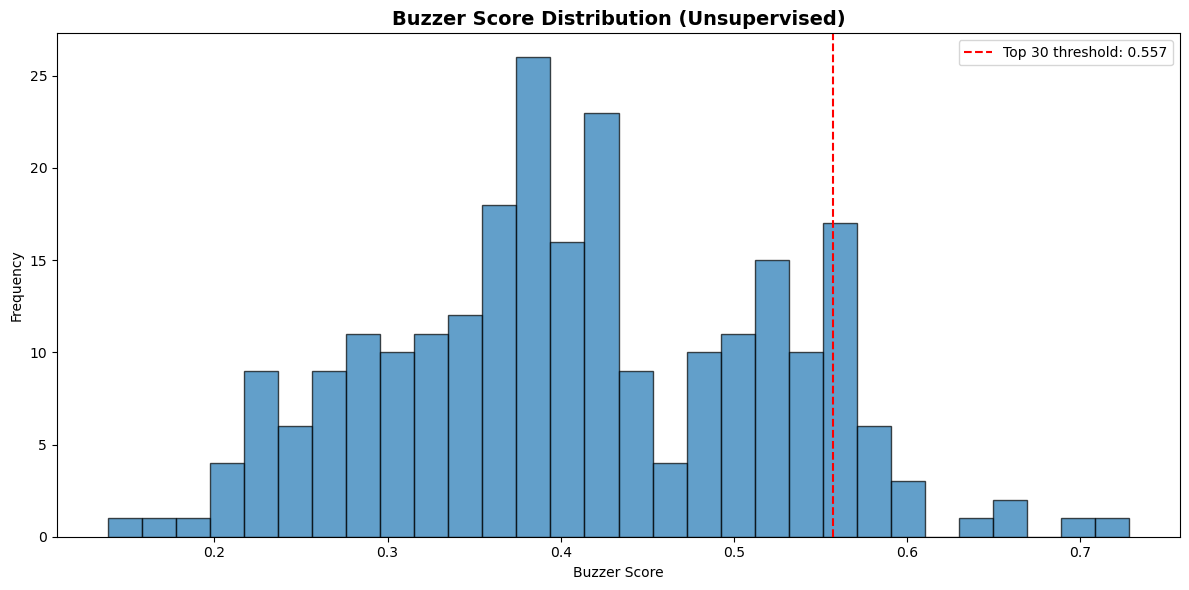

In [ ]:
suspicious = acc_features.nlargest(30, "buzzer_score")[
    ["username", "n_posts", "post_rate", "avg_tags", "avg_body_len", 
     "out_degree", "follower_ratio", "buzzer_score"]
].round(3)

print("=== TOP 30 SUSPICIOUS ACCOUNTS ===")
print(suspicious.to_string(index=False))

fig, ax = plt.subplots(figsize=(12, 6))
ax.hist(acc_features["buzzer_score"], bins=30, edgecolor='black', alpha=0.7)
ax.axvline(suspicious["buzzer_score"].min(), color='red', linestyle='--', 
           label=f'Top 30 threshold: {suspicious["buzzer_score"].min():.3f}')
ax.set_xlabel("Buzzer Score")
ax.set_ylabel("Frequency")
ax.set_title("Buzzer Score Distribution (Unsupervised)", fontsize=14, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.savefig("../output/unsupervised_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Feature Importance (Component Analysis)


=== FEATURE COMPARISON: Top 30 vs Others ===
          post_rate  avg_tags  avg_body_len  out_degree  follower_ratio
is_top30                                                               
False          8.19      4.08        192.20        0.35        10845.05
True          10.68     12.93        225.72        1.40            0.62


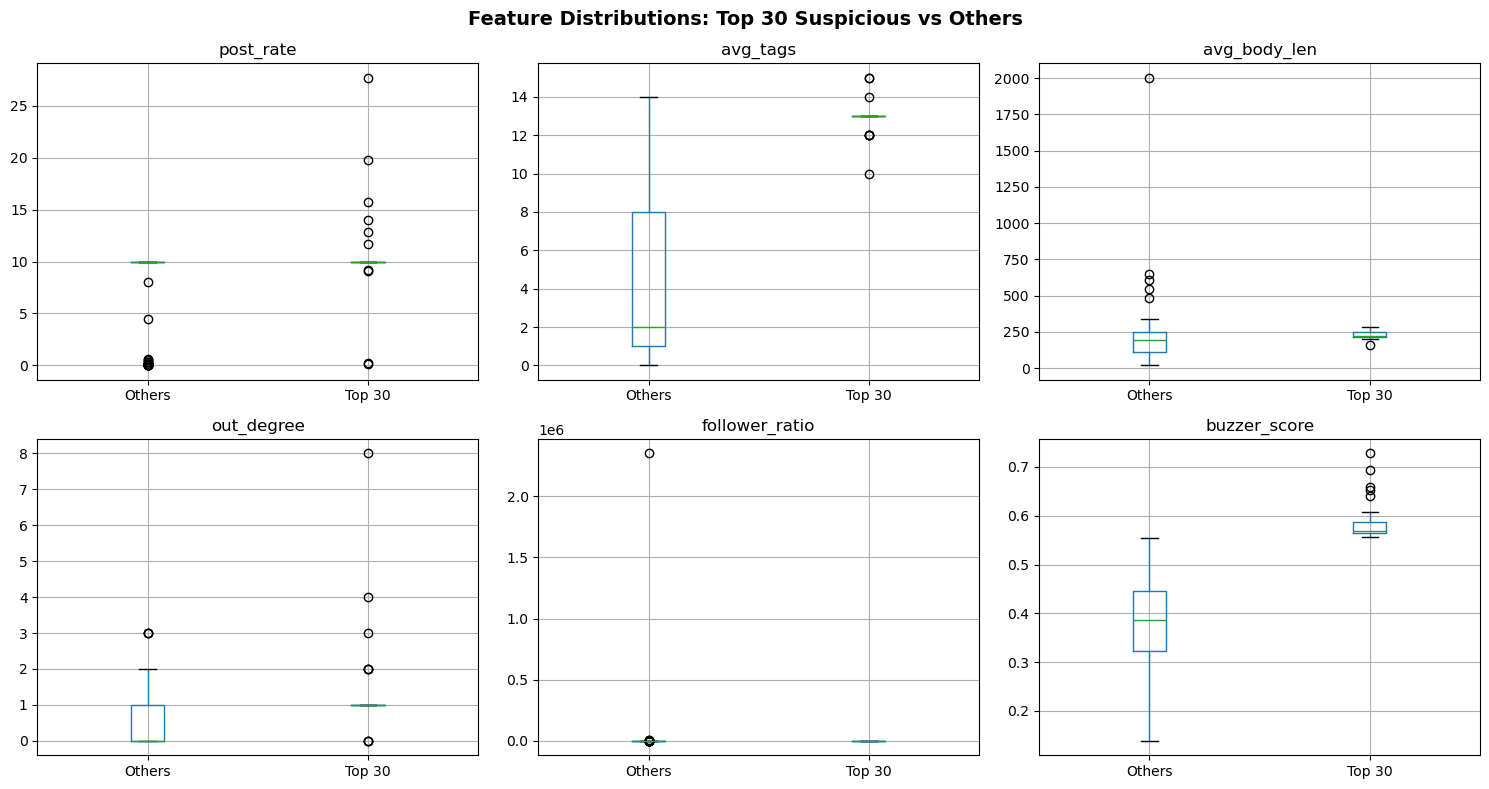

In [ ]:
top30_ids = suspicious["username"].tolist()
acc_features["is_top30"] = acc_features["username"].isin(top30_ids)

comparison = acc_features.groupby("is_top30")[[
    "post_rate", "avg_tags", "avg_body_len", "out_degree", "follower_ratio"
]].mean()

print("\n=== FEATURE COMPARISON: Top 30 vs Others ===")
print(comparison.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
features_to_plot = ["post_rate", "avg_tags", "avg_body_len", "out_degree", "follower_ratio", "buzzer_score"]

for idx, feature in enumerate(features_to_plot):
    ax = axes[idx // 3, idx % 3]
    acc_features.boxplot(column=feature, by="is_top30", ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("")
    ax.set_xticklabels(["Others", "Top 30"])

plt.suptitle("Feature Distributions: Top 30 Suspicious vs Others", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("../output/unsupervised_feature_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Export for Manual Review

In [10]:
import os
os.makedirs("../data/labels", exist_ok=True)

review_df = suspicious.copy()
review_df["label"] = ""  
review_df["notes"] = "" 

review_df.to_csv("../data/labels/top30_for_review.csv", index=False)
print("Exported: data/labels/top30_for_review.csv")

random_accounts = acc_features[~acc_features["is_top30"]].sample(20, random_state=42)[
    ["username", "n_posts", "post_rate", "avg_tags", "avg_body_len", "buzzer_score"]
]
random_accounts["label"] = ""
random_accounts["notes"] = ""
random_accounts.to_csv("../data/labels/random20_for_review.csv", index=False)
print("Exported: data/labels/random20_for_review.csv")

acc_features.to_csv("../data/features/account_features_with_scores.csv", index=False)
print("Exported: data/features/account_features_with_scores.csv")


Exported: data/labels/top30_for_review.csv
Exported: data/labels/random20_for_review.csv
Exported: data/features/account_features_with_scores.csv
